# Regression Models Template – Linear, Lasso, Elastic Net, Ridge

Plantilla para modelado predictivo basado en regresión, siguiendo las etapas del desarrollo de modelos. Este notebook incluye únicamente **Linear Regression**, **Lasso**, **Elastic Net** y **Ridge**.

## Contenido

* [1. Enunciado del problema](#1)
* [2. Inicio – Carga de librerías y datos](#2)
* [3. Análisis exploratorio](#3)
* [4. Preparación de datos](#4)
* [5. Evaluación de algoritmos](#5)
* [6. Afinación de hiperparámetros (Grid Search)](#6)
* [7. Finalización del modelo](#7)

---
# 1. Enunciado del problema <a id='1'></a>

Objetivo de este notebook:

- Trabajar un problema de modelado predictivo de principio a fin.
- Usar transformaciones de datos para mejorar el rendimiento.
- Usar afinación de hiperparámetros (Grid Search) para mejorar el rendimiento.

**Modelos implementados:**

- Linear Regression (OLS)
- Lasso (L1)
- Elastic Net (L1 + L2)
- Ridge (L2)

---
# 2. Inicio – Carga de librerías y datos <a id='2'></a>

## 2.1. Carga de librerías

In [ ]:
# Instalar dependencias (ejecutar una vez si da error)
%pip install openpyxl -q

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from matplotlib import pyplot
from pandas.plotting import scatter_matrix
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from pickle import dump, load

## 2.2. Carga de datos

In [2]:
import subprocess
import sys

try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'openpyxl', '-q'])

excel_file = 'data_usd-clp.xlsx'
dataset = pd.read_excel(excel_file, engine='openpyxl')

# Configurar columna de fecha como índice
dataset = dataset.set_index(dataset.columns[0])
dataset.index = pd.to_datetime(dataset.index)

print("Tipo de dataset:", type(dataset))
print("Dimensiones:", dataset.shape)

Tipo de dataset: <class 'pandas.DataFrame'>
Dimensiones: (1251, 10)


In [3]:
# Variables: primera columna objetivo (USDCLP), resto predictores
Y = dataset.iloc[:, 0]
X = dataset.iloc[:, 1:]

print("Variable objetivo:", Y.name)
print("Predictores:", list(X.columns))

Variable objetivo: USDCLP Curncy
Predictores: ['USSW1 Curncy', 'USSW10 Curncy', 'CHSWP1 ICCH Curncy', 'CHSWP10 Curncy', 'CCHIL1U5 CBIN Curncy', 'HGA Comdty', 'CL1 Comdty', 'VIX Index', 'JPY Curncy']


---
# 3. Análisis exploratorio <a id='3'></a>

## 3.1. Estadísticas descriptivas

In [4]:
print("Dimensiones:", dataset.shape)
print("\nTipos de datos:")
dataset.dtypes

Dimensiones: (1251, 10)

Tipos de datos:


USDCLP Curncy           float64
USSW1 Curncy            float64
USSW10 Curncy           float64
CHSWP1 ICCH Curncy      float64
CHSWP10 Curncy          float64
CCHIL1U5 CBIN Curncy    float64
HGA Comdty              float64
CL1 Comdty              float64
VIX Index               float64
JPY Curncy              float64
dtype: object

In [5]:
pd.set_option('display.width', 100)
pd.set_option('precision', 3)
dataset.head(5)

OptionError: 'Pattern matched multiple keys'

In [6]:
dataset.describe()

,USDCLP Curncy,USSW1 Curncy,USSW10 Curncy,CHSWP1 ICCH Curncy,CHSWP10 Curncy,CCHIL1U5 CBIN Curncy,HGA Comdty,CL1 Comdty,VIX Index,JPY Curncy
count,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000
mean,608.101248,0.653729,2.251509,3.596313,4.695767,86.443108,277.809872,67.313969,14.590979,108.896875
std,72.665571,0.399211,0.422041,0.753784,0.467394,19.931876,42.716189,25.334643,3.574363,8.952018
min,467.230000,0.253000,1.247300,2.280000,3.880000,50.748000,198.500000,26.210000,9.190000,85.960000
25%,551.760000,0.323500,2.002900,3.050000,4.290000,71.967500,241.125000,46.675000,12.415000,101.890000
50%,625.750000,0.490000,2.242300,3.550000,4.615000,81.888000,276.500000,53.010000,13.760000,109.180000
75%,667.240000,0.888000,2.582550,3.900000,5.065000,95.948000,314.350000,95.440000,15.745000,117.520000
max,731.400000,1.607500,3.184700,5.280000,5.615000,150.933000,366.500000,110.530000,40.740000,125.630000


## 3.2. Visualización de datos

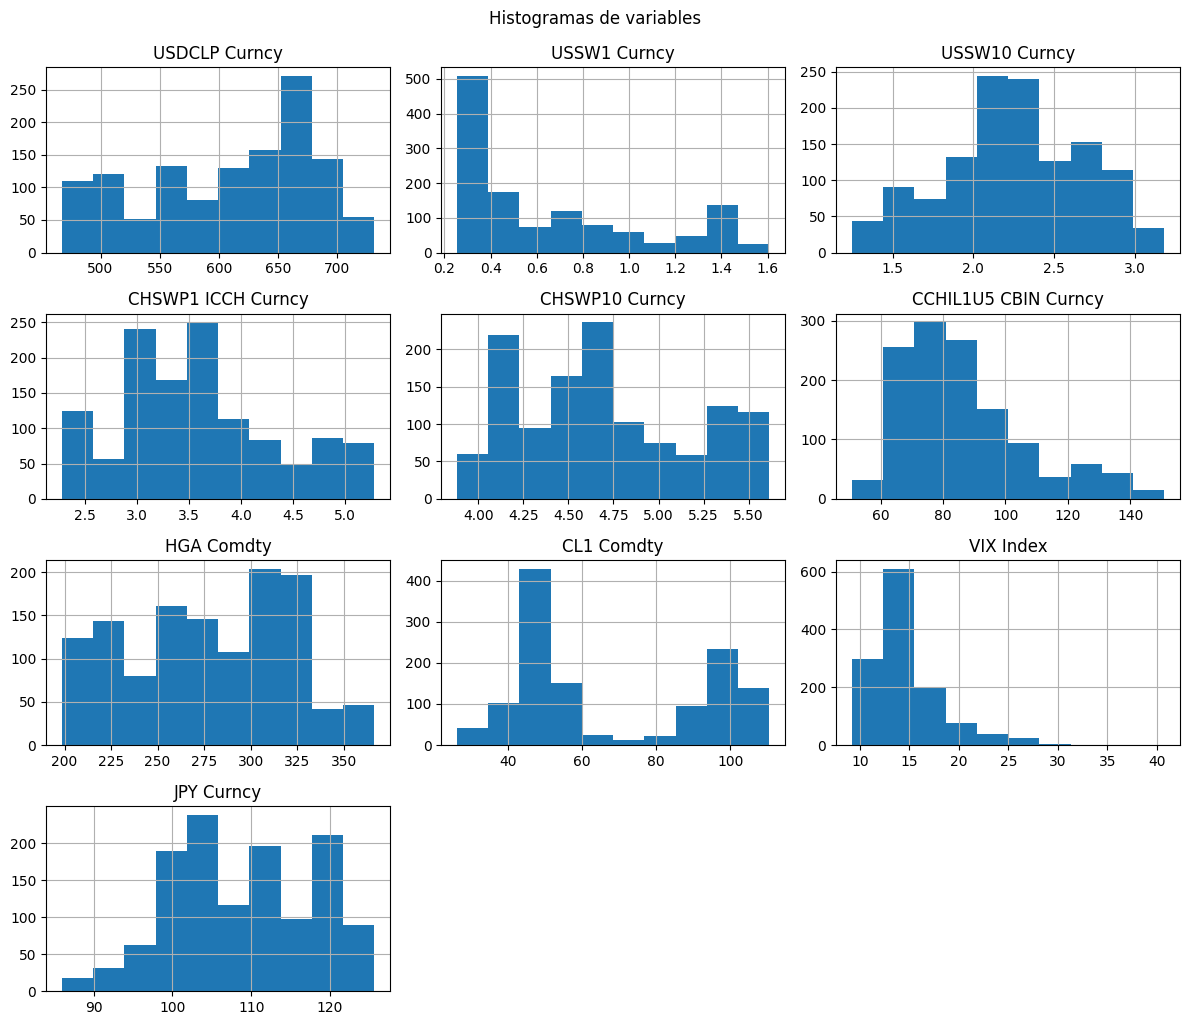

In [7]:
# Histogramas
dataset.hist(figsize=(12, 10))
pyplot.tight_layout()
pyplot.suptitle('Histogramas de variables', y=1.02)
pyplot.show()

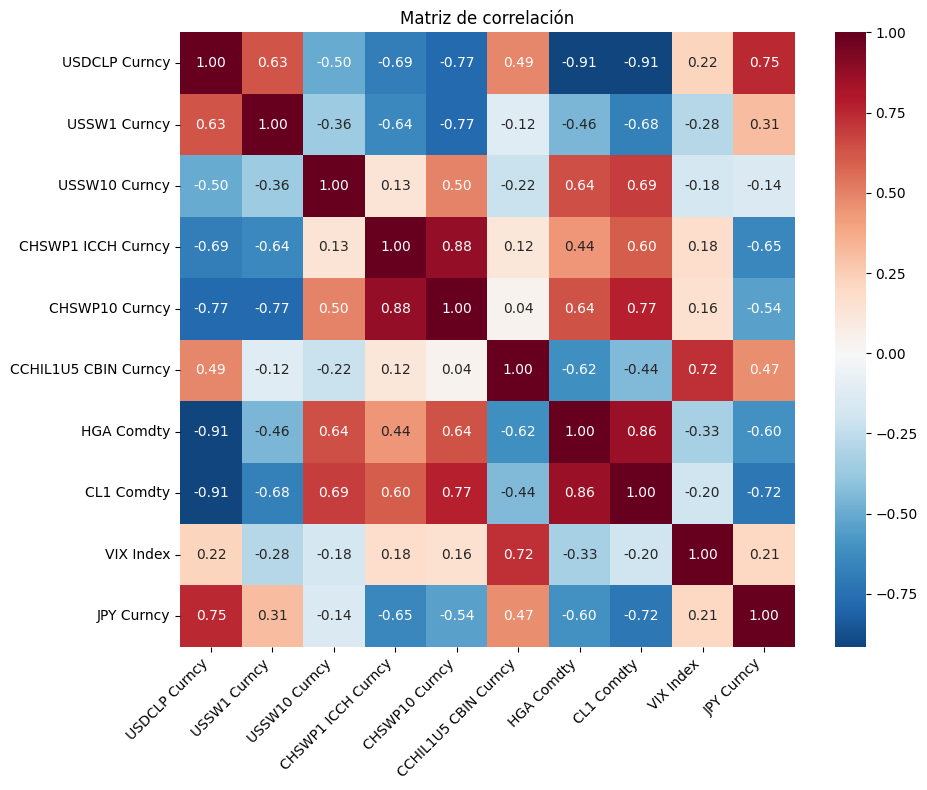

In [8]:
# Matriz de correlación
corr = dataset.corr()
fig, ax = pyplot.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, ax=ax)
pyplot.title('Matriz de correlación')
pyplot.xticks(rotation=45, ha='right')
pyplot.tight_layout()
pyplot.show()

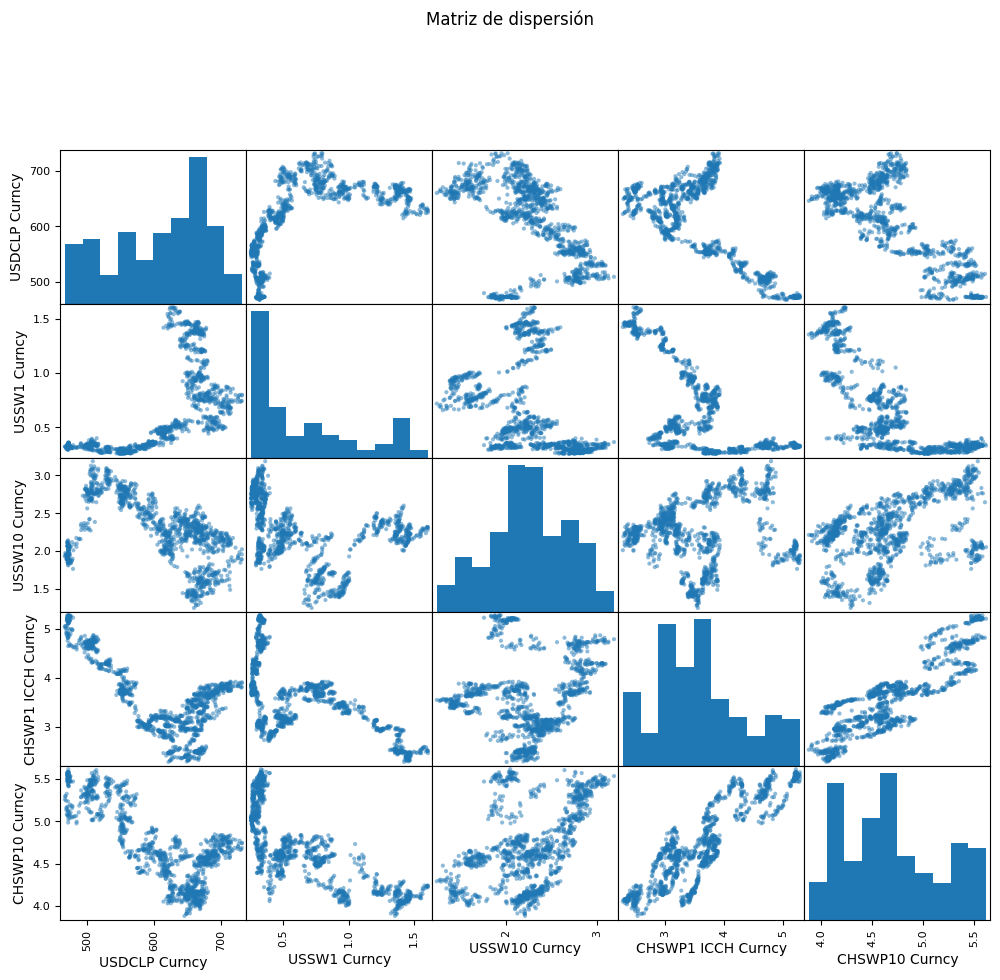

In [9]:
# Scatter matrix (muestra de variables para no saturar)
numeric_cols = dataset.select_dtypes(include=[np.number]).columns.tolist()
cols_plot = numeric_cols[:5] if len(numeric_cols) >= 5 else numeric_cols
scatter_matrix(dataset[cols_plot], figsize=(12, 10), alpha=0.5)
pyplot.suptitle('Matriz de dispersión', y=1.02)
pyplot.show()

---
# 4. Preparación de datos <a id='4'></a>

## 4.1. Limpieza de datos

In [10]:
# Eliminar filas con NaN
dataset_clean = dataset.dropna()
print("Filas originales:", len(dataset))
print("Filas después de limpieza:", len(dataset_clean))

Filas originales: 1251
Filas después de limpieza: 1251


## 4.2. División Train/Test (series temporales)

In [11]:
# División temporal: 80% entrenamiento, 20% prueba
split_idx = int(len(dataset_clean) * 0.8)

X_train = dataset_clean.iloc[:split_idx, 1:]
Y_train = dataset_clean.iloc[:split_idx, 0]
X_validation = dataset_clean.iloc[split_idx:, 1:]
Y_validation = dataset_clean.iloc[split_idx:, 0]

print("Entrenamiento: X", X_train.shape, "Y", Y_train.shape)
print("Prueba: X", X_validation.shape, "Y", Y_validation.shape)

Entrenamiento: X (1000, 9) Y (1000,)
Prueba: X (251, 9) Y (251,)


## 4.3. Transformación de datos (StandardScaler)

In [12]:
# Estandarización: media 0, desv. estándar 1 (recomendado para Ridge/Lasso/ElasticNet)
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_validation_scaled = scaler.transform(X_validation)

print("Transformación aplicada: StandardScaler")
print("Media train (aprox. 0):", X_train_scaled.mean(axis=0).round(4))
print("Desv. train (aprox. 1):", X_train_scaled.std(axis=0).round(4))

Transformación aplicada: StandardScaler
Media train (aprox. 0): [-0.  0.  0. -0.  0.  0.  0. -0. -0.]
Desv. train (aprox. 1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
# 5. Evaluación de algoritmos <a id='5'></a>

## 5.1. Definición de modelos (Linear, Lasso, Elastic Net, Ridge)

In [13]:
models = []
models.append(('LR', LinearRegression()))
models.append(('Lasso', Lasso(alpha=0.1)))
models.append(('EN', ElasticNet(alpha=0.1, l1_ratio=0.5)))
models.append(('Ridge', Ridge(alpha=0.1)))

## 5.2. Evaluación con validación cruzada

In [14]:
results = []
names = []
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models:
    cv_results = cross_val_score(model, X_train_scaled, Y_train, cv=kfold, scoring='neg_mean_squared_error')
    results.append(cv_results)
    names.append(name)
    msg = "%s: %.4f (%.4f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

LR: -195.8519 (23.3802)
Lasso: -196.9070 (23.8810)
EN: -220.3959 (26.8297)
Ridge: -195.8499 (23.3849)


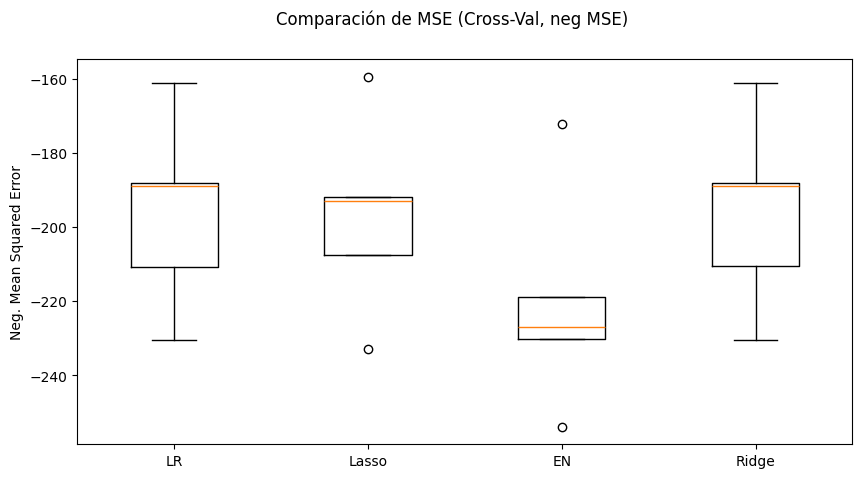

In [15]:
# Comparación visual
fig = pyplot.figure(figsize=(10, 5))
fig.suptitle('Comparación de MSE (Cross-Val, neg MSE)')
ax = fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(names)
pyplot.ylabel('Neg. Mean Squared Error')
pyplot.show()

## 5.3. Métricas en muestra de validación

In [16]:
# Entrenar cada modelo en train y evaluar en validation
print("Métricas en validación (datos escalados):\n")

for name, model in models:
    model.fit(X_train_scaled, Y_train)
    pred = model.predict(X_validation_scaled)
    mse = mean_squared_error(Y_validation, pred)
    mae = mean_absolute_error(Y_validation, pred)
    r2 = r2_score(Y_validation, pred)
    print("%s:  MSE=%.4f  MAE=%.4f  R2=%.4f" % (name, mse, mae, r2))

Métricas en validación (datos escalados):

LR:  MSE=595.4302  MAE=21.8443  R2=-1.5599
Lasso:  MSE=460.2627  MAE=19.2392  R2=-0.9788
EN:  MSE=1165.6734  MAE=31.7427  R2=-4.0115
Ridge:  MSE=596.5919  MAE=21.8728  R2=-1.5649


---
# 6. Afinación de hiperparámetros (Grid Search) <a id='6'></a>

In [17]:
# Grid Search para Lasso, Elastic Net y Ridge
param_grid_lasso = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}
param_grid_en = {'alpha': [0.01, 0.1, 1.0], 'l1_ratio': [0.2, 0.5, 0.8]}
param_grid_ridge = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}

grids = [
    ('Lasso', Lasso(), param_grid_lasso),
    ('ElasticNet', ElasticNet(), param_grid_en),
    ('Ridge', Ridge(), param_grid_ridge)
]

best_models = {}

for name, model, param_grid in grids:
    grid = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
    grid.fit(X_train_scaled, Y_train)
    best_models[name] = grid.best_estimator_
    print("%s - Mejores params: %s (MSE=%.4f)" % (name, grid.best_params_, -grid.best_score_))

Lasso - Mejores params: {'alpha': 1.0} (MSE=610.2862)
ElasticNet - Mejores params: {'alpha': 0.1, 'l1_ratio': 0.8} (MSE=551.8059)
Ridge - Mejores params: {'alpha': 10.0} (MSE=582.4401)


---
# 7. Finalización del modelo <a id='7'></a>

## 7.1. Resultados en test con modelos afinados

In [18]:
# Linear Regression (sin afinación)
lr = LinearRegression()
lr.fit(X_train_scaled, Y_train)
best_models['LR'] = lr

print("Métricas finales en validación:\n")
for name, model in best_models.items():
    pred = model.predict(X_validation_scaled)
    mse = mean_squared_error(Y_validation, pred)
    r2 = r2_score(Y_validation, pred)
    print("%s:  MSE=%.4f  R2=%.4f" % (name, mse, r2))

Métricas finales en validación:

Lasso:  MSE=111.0227  R2=0.5227
ElasticNet:  MSE=838.0453  R2=-2.6030
Ridge:  MSE=756.7398  R2=-2.2534
LR:  MSE=595.4302  R2=-1.5599


## 7.2. Coeficientes (interpretación)

In [19]:
feature_names = X_train.columns.tolist()

for name, model in best_models.items():
    coef = model.coef_ if hasattr(model, 'coef_') else None
    if coef is not None:
        print("\n%s - Coeficientes:" % name)
        for f, c in zip(feature_names, coef):
            print("  %s: %.4f" % (f[:30], c))


Lasso - Coeficientes:
  USSW1 Curncy: 6.7530
  USSW10 Curncy: 0.0000
  CHSWP1 ICCH Curncy: -17.4259
  CHSWP10 Curncy: 0.0000
  CCHIL1U5 CBIN Curncy: 10.0226
  HGA Comdty: -44.3183
  CL1 Comdty: -0.0000
  VIX Index: 1.2178
  JPY Curncy: 7.7691

ElasticNet - Coeficientes:
  USSW1 Curncy: 13.8514
  USSW10 Curncy: 0.1839
  CHSWP1 ICCH Curncy: -23.2356
  CHSWP10 Curncy: 4.5557
  CCHIL1U5 CBIN Curncy: 12.1366
  HGA Comdty: -34.8379
  CL1 Comdty: -3.0817
  VIX Index: 1.8562
  JPY Curncy: 6.7524

Ridge - Coeficientes:
  USSW1 Curncy: 14.0028
  USSW10 Curncy: -1.2232
  CHSWP1 ICCH Curncy: -26.8364
  CHSWP10 Curncy: 9.3423
  CCHIL1U5 CBIN Curncy: 11.9995
  HGA Comdty: -37.5632
  CL1 Comdty: -1.9236
  VIX Index: 1.5328
  JPY Curncy: 6.0923

LR - Coeficientes:
  USSW1 Curncy: 14.2555
  USSW10 Curncy: -4.7160
  CHSWP1 ICCH Curncy: -31.5533
  CHSWP10 Curncy: 15.2239
  CCHIL1U5 CBIN Curncy: 12.5208
  HGA Comdty: -40.8813
  CL1 Comdty: 2.2236
  VIX Index: 0.9899
  JPY Curncy: 6.2612


## 7.3. Guardar modelo para uso posterior

In [20]:
# Ejemplo: guardar el mejor modelo según criterio (ej. Ridge con menor MSE)
scores = {}
for name, model in best_models.items():
    pred = model.predict(X_validation_scaled)
    scores[name] = mean_squared_error(Y_validation, pred)

best_name = min(scores, key=scores.get)
best_model = best_models[best_name]

dump(best_model, open('modelo_regresion_final.pkl', 'wb'))
dump(scaler, open('scaler_final.pkl', 'wb'))

print("Modelo guardado: %s" % best_name)
print("Archivos: modelo_regresion_final.pkl, scaler_final.pkl")

Modelo guardado: Lasso
Archivos: modelo_regresion_final.pkl, scaler_final.pkl
